In [ ]:
# ============================================
# TASK 8 - STEP 2
# Load Task 5-7 outputs
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# File paths
X_train_path = "/content/ThreatLens_X_train.csv"
X_test_path = "/content/ThreatLens_X_test.csv"
y_train_path = "/content/ThreatLens_y_train.csv"
y_test_path = "/content/ThreatLens_y_test.csv"
model_path = "/content/ThreatLens_LSTM_Model.keras"

# Load datasets
X_train = pd.read_csv(X_train_path)
X_test = pd.read_csv(X_test_path)

y_train = pd.read_csv(y_train_path)
y_test = pd.read_csv(y_test_path)

# Remove unnecessary index columns if present
for df_name, df in [
    ("X_train", X_train),
    ("X_test", X_test),
    ("y_train", y_train),
    ("y_test", y_test)
]:
    unwanted_cols = [
        col for col in df.columns
        if col.lower().startswith("unnamed")
        or col.lower() in ["index", "level_0"]
    ]

    if unwanted_cols:
        df.drop(columns=unwanted_cols, inplace=True)

# Convert target DataFrames to Series
if y_train.shape[1] == 1:
    y_train = y_train.iloc[:, 0]

if y_test.shape[1] == 1:
    y_test = y_test.iloc[:, 0]

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

print("\nTarget classes:")
print(sorted(y_train.unique()))

print("\nTask 5-7 files loaded successfully.")

X_train shape: (1785444, 20)
X_test shape : (446362, 20)
y_train shape: (1785444,)
y_test shape : (446362,)

Target classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]

Task 5-7 files loaded successfully.


In [ ]:
# ============================================
# TASK 8 - STEP 3
# Load trained LSTM model
# ============================================

from tensorflow.keras.models import load_model

# Direct path to the existing model file
model_path = "/content/ThreatLens_LSTM_Model.keras"

# Load the model directly from the file
lstm_model = load_model(model_path)

print("LSTM model loaded successfully!")
print("\nModel Summary:\n")

lstm_model.summary()

LSTM model loaded successfully!

Model Summary:



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73,007 (285.19 KB)

 Trainable params: 24,335 (95.06 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 48,672 (190.13 KB)

In [ ]:
# ============================================
# TASK 8 - STEP 4
# Check LSTM input requirements
# ============================================

print("Model input shape:", lstm_model.input_shape)
print("X_test shape:", X_test.shape)

Model input shape: (None, 1, 20)
X_test shape: (446362, 20)


In [ ]:
# Convert test data to NumPy
X_test_np = X_test.values.astype("float32")

# Reshape if the LSTM expects 3D input
if len(lstm_model.input_shape) == 3 and X_test_np.ndim == 2:

    timesteps = lstm_model.input_shape[1]

    X_test_lstm = X_test_np.reshape(
        X_test_np.shape[0],
        timesteps,
        X_test_np.shape[1] // timesteps
    )

else:
    X_test_lstm = X_test_np

print("Final LSTM test shape:", X_test_lstm.shape)

Final LSTM test shape: (446362, 1, 20)


In [ ]:
# ============================================
# TASK 8 - STEP 5
# Generate LSTM predictions
# ============================================

y_pred_prob = lstm_model.predict(
    X_test_lstm,
    verbose=1
)

print("Prediction shape:", y_pred_prob.shape)

13949/13949 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step
Prediction shape: (446362, 15)


In [ ]:
# ============================================
# Convert probabilities to predicted labels
# ============================================

if y_pred_prob.shape[1] == 1:
    y_pred_lstm = (y_pred_prob.ravel() >= 0.5).astype(int)

else:
    y_pred_lstm = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully.")

print("\nFirst 20 predictions:")
print(y_pred_lstm[:20])

Predictions generated successfully.

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
# ============================================
# TASK 8 - STEP 6
# Evaluate LSTM
# ============================================

accuracy_lstm = accuracy_score(y_test, y_pred_lstm)

precision_lstm = precision_score(
    y_test,
    y_pred_lstm,
    average="weighted",
    zero_division=0
)

recall_lstm = recall_score(
    y_test,
    y_pred_lstm,
    average="weighted",
    zero_division=0
)

f1_lstm = f1_score(
    y_test,
    y_pred_lstm,
    average="weighted",
    zero_division=0
)

print("========== LSTM PERFORMANCE ==========")
print("Accuracy :", accuracy_lstm)
print("Precision:", precision_lstm)
print("Recall   :", recall_lstm)
print("F1 Score :", f1_lstm)

========== LSTM PERFORMANCE ==========
Accuracy : 0.9916077085414977
Precision: 0.9912565432849149
Recall   : 0.9916077085414977
F1 Score : 0.9909425452852043


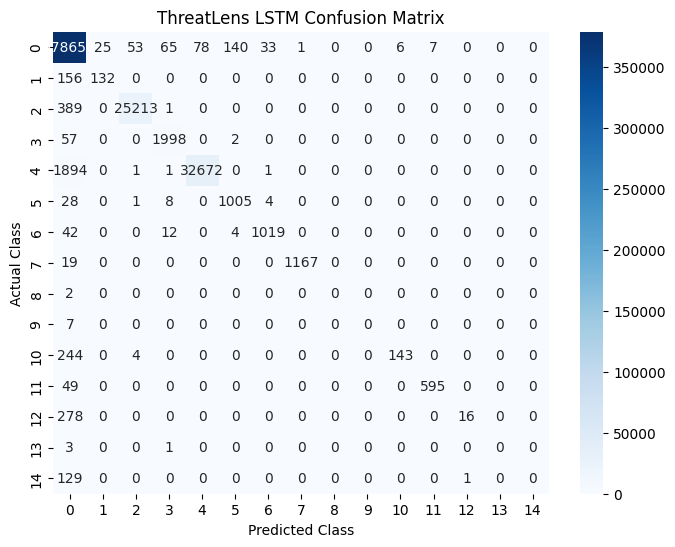

In [ ]:
# ============================================
# TASK 8 - STEP 7
# LSTM Confusion Matrix
# ============================================

cm = confusion_matrix(y_test, y_pred_lstm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("ThreatLens LSTM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
# ============================================
# TASK 8 - STEP 8
# Find LSTM layers
# ============================================

for i, layer in enumerate(lstm_model.layers):

    print(
        i,
        "|",
        layer.name,
        "|",
        layer.__class__.__name__,
        "|",
        layer.output.shape
    )

0 | lstm | LSTM | (None, 64)
1 | dropout | Dropout | (None, 64)
2 | dense | Dense | (None, 32)
3 | dropout_1 | Dropout | (None, 32)
4 | dense_1 | Dense | (None, 15)


In [ ]:
# ============================================
# TASK 8 - STEP 9
# Extract LSTM activations
# ============================================

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input
import numpy as np

# Find the first LSTM layer
lstm_layer = None
for layer in lstm_model.layers:
    if "LSTM" in layer.__class__.__name__:
        lstm_layer = layer
        break

if lstm_layer is None:
    raise ValueError("No LSTM layer found in the model.")

print("Selected LSTM layer:", lstm_layer.name)

# Safely construct an activation extractor by passing input explicitly
input_shape = (1, 20)
inputs = Input(shape=input_shape)

x = inputs
for layer in lstm_model.layers:
    x = layer(x)
    if layer == lstm_layer:
        break

activation_model = Model(inputs=inputs, outputs=x)

# Get activations for a small sample
sample_size = min(100, len(X_test_lstm))
sample_data = X_test_lstm[:sample_size]

activations = activation_model.predict(
    sample_data,
    verbose=0
)

print("Activation shape:", activations.shape)

Selected LSTM layer: lstm
Activation shape: (100, 64)


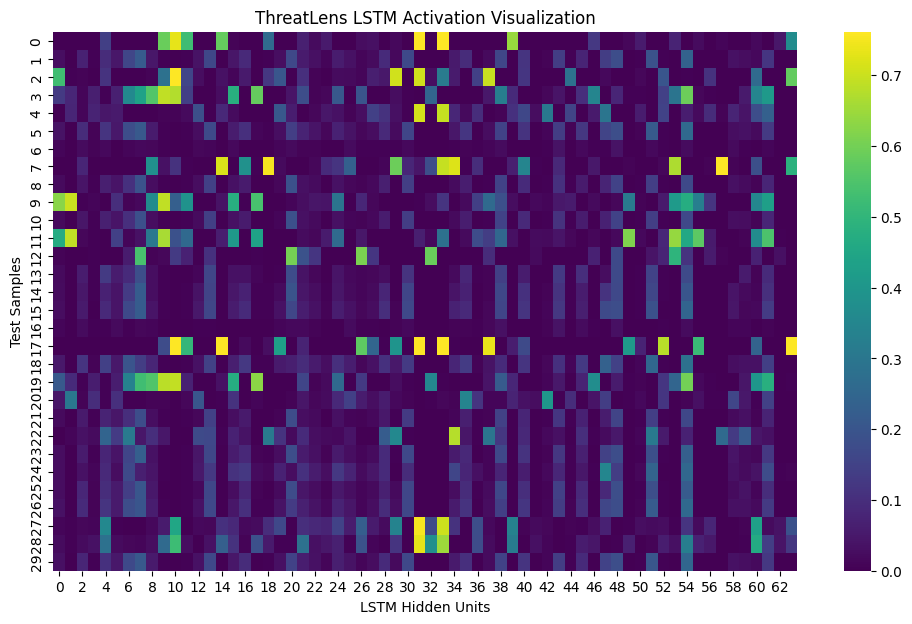

In [ ]:
# ============================================
# TASK 8 - STEP 10
# Activation Heatmap
# ============================================

# Handle both 2D and 3D activations

if activations.ndim == 3:

    # Average across time steps
    activation_visual = np.mean(
        np.abs(activations),
        axis=1
    )

else:

    activation_visual = np.abs(activations)

plt.figure(figsize=(12, 7))

sns.heatmap(
    activation_visual[:30],
    cmap="viridis"
)

plt.title("ThreatLens LSTM Activation Visualization")
plt.xlabel("LSTM Hidden Units")
plt.ylabel("Test Samples")

plt.show()

Compare the performance and interpretability
with the basic model.

In [ ]:
# ============================================
# TASK 8 - STEP 11
# Feature Importance using Permutation
# ============================================

from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np
import pandas as pd

# Use a manageable sample
importance_size = min(1000, len(X_test))

X_imp = X_test.iloc[:importance_size].copy()
y_imp = y_test.iloc[:importance_size].copy()

# Create a lightweight wrapper that implements scikit-learn's interface
class LSTMScikitWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model):
        self.model = model
        self.classes_ = np.arange(15)

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X_np = X.values.astype("float32")
        else:
            X_np = np.array(X).astype("float32")

        if len(self.model.input_shape) == 3 and X_np.ndim == 2:
            timesteps = self.model.input_shape[1]
            X_np = X_np.reshape(
                X_np.shape[0],
                timesteps,
                X_np.shape[1] // timesteps
            )

        probabilities = self.model.predict(X_np, verbose=0)

        if probabilities.shape[1] == 1:
            return (probabilities.ravel() >= 0.5).astype(int)

        return np.argmax(probabilities, axis=1)

# Instantiate the wrapper with our model
wrapped_lstm = LSTMScikitWrapper(lstm_model)

# Calculate permutation importance using the wrapped estimator
result = permutation_importance(
    wrapped_lstm,
    X_imp,
    y_imp,
    n_repeats=3,
    random_state=42,
    scoring="accuracy"
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                            Feature  Importance
0          numeric__Avg Packet Size    0.161333
15             numeric__Fwd IAT Max    0.118333
12   numeric__Bwd Packet Length Std    0.112333
13   numeric__Fwd Packet Length Max    0.090000
6        numeric__Packet Length Std    0.064667
16      numeric__Init Fwd Win Bytes    0.029667
7   numeric__Packet Length Variance    0.027667
5       numeric__Packet Length Mean    0.025667
2     numeric__Avg Bwd Segment Size    0.020000
1   numeric__Bwd Packet Length Mean    0.019667
17           numeric__Fwd IAT Total    0.013667
9    numeric__Bwd Packet Length Max    0.012333
19            numeric__Fwd IAT Mean    0.011667
14      numeric__Init Bwd Win Bytes    0.011000
18            numeric__Flow IAT Max    0.011000


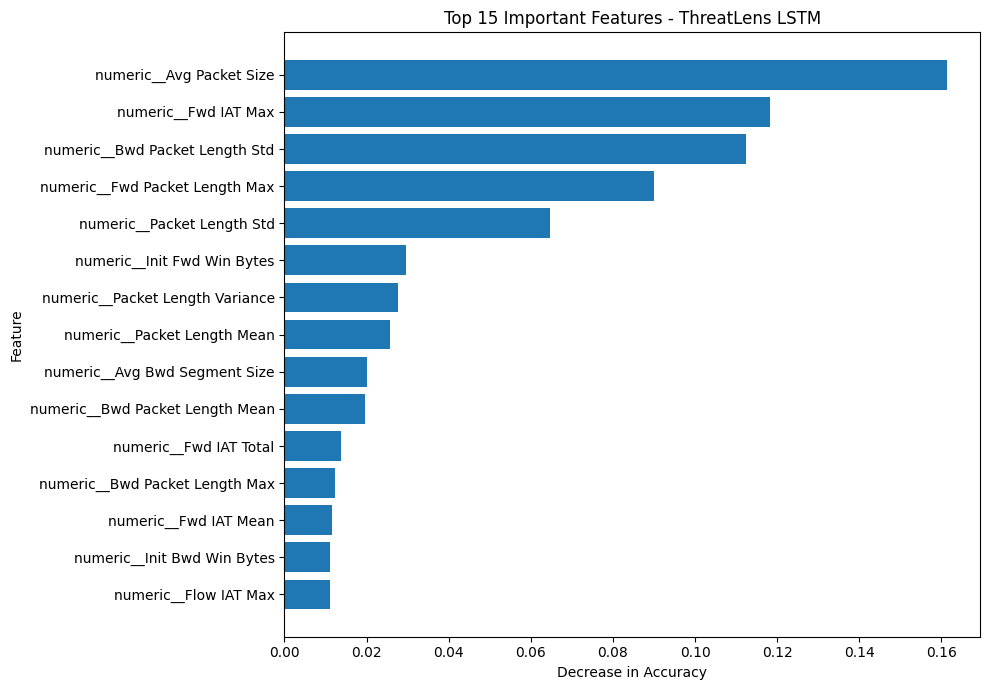

In [ ]:
# ============================================
# TASK 8 - STEP 12
# Top Feature Importance Visualization
# ============================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Decrease in Accuracy")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - ThreatLens LSTM")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TASK 8 - STEP 13
# Load Task 6 evaluation results
# ============================================

import glob

evaluation_files = glob.glob(
    "/content/ThreatLens_Model_Evaluation*.csv"
)

print("Evaluation files found:")

for file in evaluation_files:
    print(file)

Evaluation files found:
/content/ThreatLens_Model_Evaluation.csv


In [ ]:
# Load evaluation results
import pandas as pd

try:
    evaluation_df = pd.read_csv("/content/ThreatLens_Model_Evaluation.csv")
    print("Task 6 Model Evaluation Results Loaded Successfully:")
    print(evaluation_df)
except FileNotFoundError:
    print("Error: /content/ThreatLens_Model_Evaluation.csv not found.")

Task 6 Model Evaluation Results Loaded Successfully:
                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.699941   0.969068  0.699941  0.800797
1        Decision Tree  0.992977   0.996378  0.992977  0.994422
2        Random Forest  0.995909   0.997368  0.995909  0.996503
